In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML


url = 'https://raw.githubusercontent.com/amankharwal/Website-data/master/Groceries_dataset.csv'

df = pd.read_csv(url, encoding="ISO-8859-1")

df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

df.fillna('Unknown', inplace=True)

display(HTML("<h4 style='color: #3498db;'>1. First 5 Rows of the Dataset</h4>"))
display(df.head())
display(HTML("<div style='margin-bottom: 30px;'></div>"))
display(HTML("<h4 style='color: #2ecc71;'>2. Dataset Info</h4>"))
print(df.info())

,Member_number,Date,itemDescription
0,1808,2015-07-21,tropical fruit
1,2552,2015-01-05,whole milk
2,2300,2015-09-19,pip fruit
3,1187,2015-12-12,other vegetables
4,3037,2015-02-01,whole milk


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Member_number    38765 non-null  int64         
 1   Date             38765 non-null  datetime64[ns]
 2   itemDescription  38765 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(1)
memory usage: 908.7+ KB
None


   Member_number       Date  Basket_Size
0           1000 2014-06-24            3
1           1000 2015-03-15            4
2           1000 2015-05-27            2
3           1000 2015-07-24            2
4           1000 2015-11-25            2


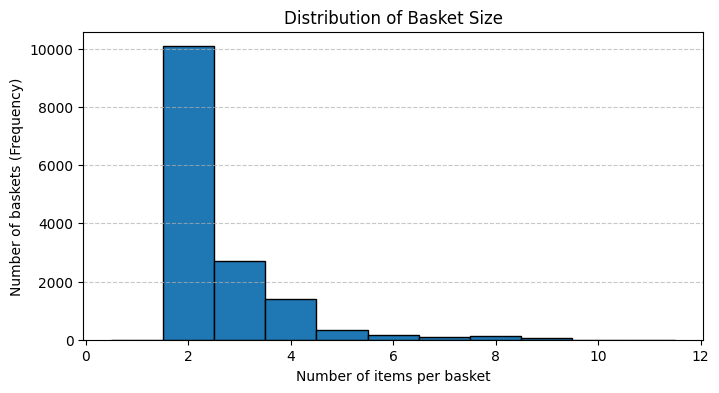

In [5]:
basket_sizes = df.groupby(['Member_number', 'Date'])['itemDescription'].count().reset_index()
basket_sizes.rename(columns={'itemDescription': 'Basket_Size'}, inplace=True)
print(basket_sizes.head())

plt.figure(figsize=(8, 4), facecolor='white')
plt.hist(basket_sizes['Basket_Size'], bins=range(1, basket_sizes['Basket_Size'].max() + 2), edgecolor='black', align='left')
plt.title('Distribution of Basket Size')
plt.xlabel('Number of items per basket')
plt.ylabel('Number of baskets (Frequency)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

   Member_number  Purchase_Frequency
0           1000                   5
1           1001                   5
2           1002                   4
3           1003                   4
4           1004                   8


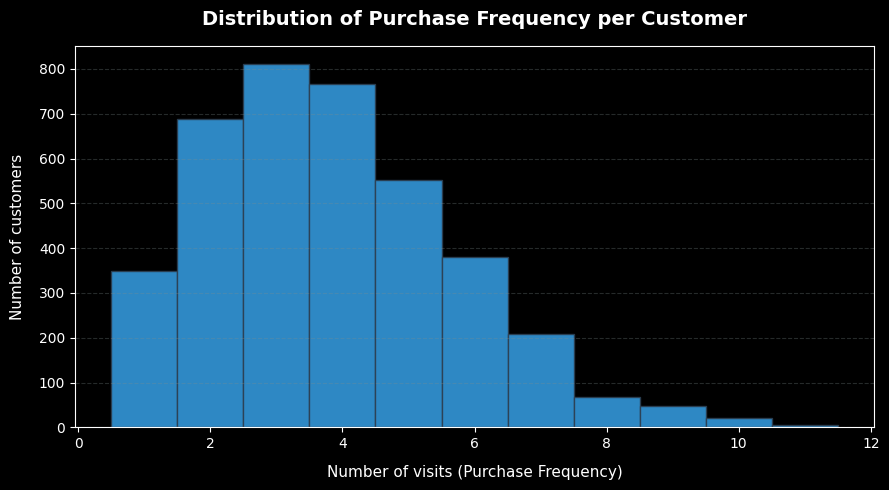

In [6]:
customer_frequency = df.groupby('Member_number')['Date'].nunique().reset_index()
customer_frequency.rename(columns={'Date': 'Purchase_Frequency'}, inplace=True)
print(customer_frequency.head())

plt.style.use('dark_background')

plt.figure(figsize=(9, 5))


plt.hist(
    customer_frequency['Purchase_Frequency'],
    bins=range(1, customer_frequency['Purchase_Frequency'].max() + 2),
    color='#3498db',         # Sütunların rəngi (parlaq mavi)
    edgecolor='#2c3e50',     # Sütun haşiyəsi
    alpha=0.9,
    align='left'
)

plt.title('Distribution of Purchase Frequency per Customer', fontsize=14, fontweight='bold', pad=15, color='white')
plt.xlabel('Number of visits (Purchase Frequency)', fontsize=11, labelpad=10, color='white')
plt.ylabel('Number of customers', fontsize=11, labelpad=10, color='white')

plt.grid(axis='y', linestyle='--', alpha=0.3, color='#7f8c8d')
plt.xticks(fontsize=10, color='white')
plt.yticks(fontsize=10, color='white')

plt.tight_layout()
plt.show()

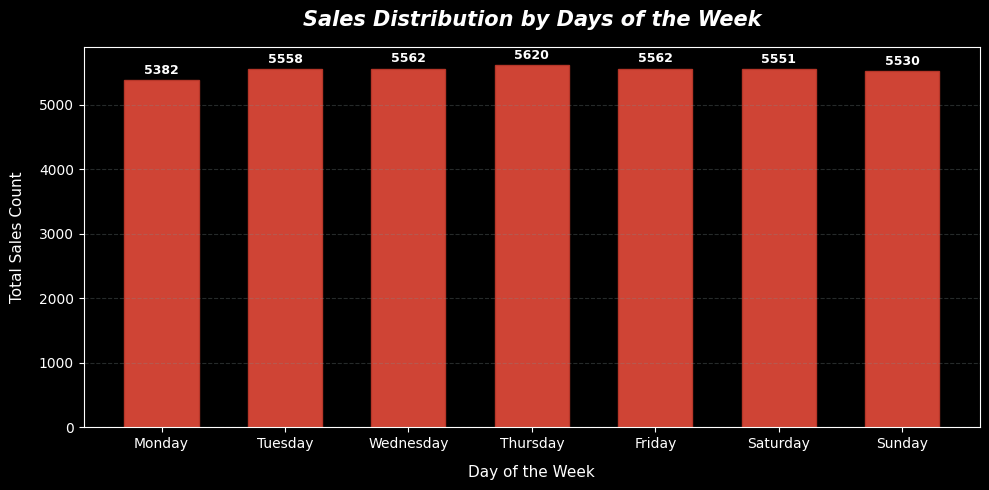

In [8]:
df['Day_Of_Week'] = df['Date'].dt.day_name()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sales_by_day = df['Day_Of_Week'].value_counts().reindex(day_order)

plt.style.use('dark_background')
plt.figure(figsize=(10, 5))

bars = plt.bar(
    sales_by_day.index,
    sales_by_day.values,
    color='#e74c3c',
    edgecolor='#c0392b',
    alpha=0.9,
    width=0.6
)

plt.title('Sales Distribution by Days of the Week', fontsize=15, fontweight='bold', fontstyle='italic', pad=15, color='white')
plt.xlabel('Day of the Week', fontsize=11, labelpad=10, color='white')
plt.ylabel('Total Sales Count', fontsize=11, labelpad=10, color='white')

plt.grid(axis='y', linestyle='--', alpha=0.3, color='#7f8c8d')
plt.xticks(fontsize=10, color='white')
plt.yticks(fontsize=10, color='white')

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 50,
        f'{int(height)}',
        ha='center',
        va='bottom',
        fontsize=9,
        color='white',
        fontweight='bold'
    )
plt.tight_layout()
plt.show()

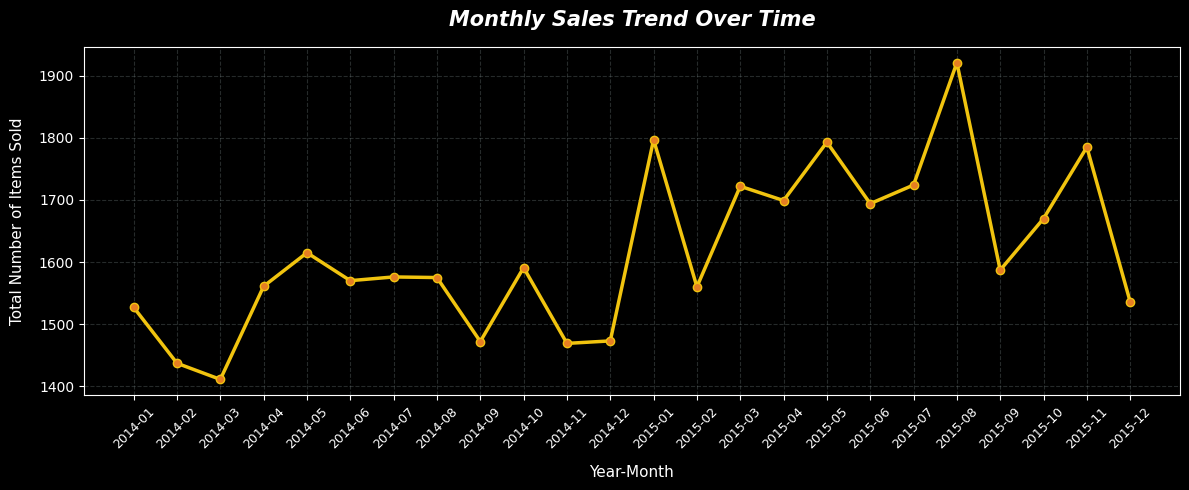

In [9]:
# Monthly Sales Trend Analysis Over Time

import matplotlib.pyplot as plt

df['Year_Month'] = df['Date'].dt.to_period('M')
monthly_sales = df['Year_Month'].value_counts().sort_index()

plt.style.use('dark_background')
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    color='#f1c40f',
    linewidth=2.5,
    markersize=6,
    markerfacecolor='#e67e22'
)

plt.title('Monthly Sales Trend Over Time', fontsize=15, fontweight='bold', fontstyle='italic', pad=15, color='white')
plt.xlabel('Year-Month', fontsize=11, labelpad=10, color='white')
plt.ylabel('Total Number of Items Sold', fontsize=11, labelpad=10, color='white')

plt.grid(True, linestyle='--', alpha=0.3, color='#7f8c8d')
plt.xticks(rotation=45, fontsize=9, color='white')
plt.yticks(fontsize=10, color='white')

plt.tight_layout()
plt.show()

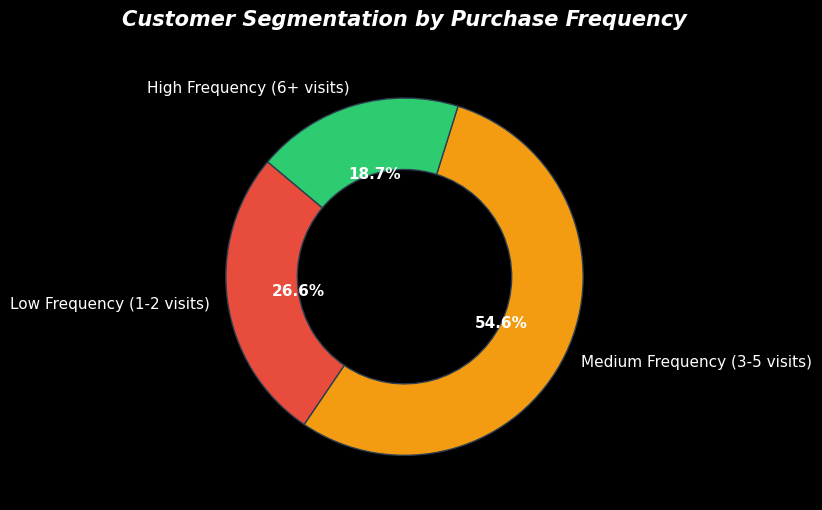

In [10]:
# Customer Segmentation Based on Purchase Frequency

customer_freq = df.groupby('Member_number')['Date'].nunique().reset_index()
customer_freq.rename(columns={'Date': 'Purchase_Frequency'}, inplace=True)


def segment_customer(freq):
    if freq <= 2:
        return 'Low Frequency (1-2 visits)'
    elif freq <= 5:
        return 'Medium Frequency (3-5 visits)'
    else:
        return 'High Frequency (6+ visits)'

customer_freq['Segment'] = customer_freq['Purchase_Frequency'].apply(segment_customer)


segment_counts = customer_freq['Segment'].value_counts().reindex([
    'Low Frequency (1-2 visits)',
    'Medium Frequency (3-5 visits)',
    'High Frequency (6+ visits)'
])

plt.style.use('dark_background')
plt.figure(figsize=(8, 8))

colors = ['#e74c3c', '#f39c12', '#2ecc71']

wedges, texts, autotexts = plt.pie(
    segment_counts.values,
    labels=segment_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='#2c3e50')
)

plt.setp(texts, color='white', fontsize=11)
plt.setp(autotexts, color='white', fontsize=11, fontweight='bold')

plt.title('Customer Segmentation by Purchase Frequency', fontsize=15, fontweight='bold', fontstyle='italic', pad=20, color='white')

plt.tight_layout()
plt.show()